# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 03: Baseline Model & Failure Diagnosis
**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below (see [`agents.md`](../agents.md)).


### Planned Steps & Workflow (Referencing `docs/project_cv_workflow.html`)
**Model ladder rung: M1 (Base OLS)**
- **1. Setup & Ingestion**:
  - Load the base processed training dataset (`data/train_base.csv`) from Notebook 02.
  - Connect to shared expanding-window CV splits ($k=8$ monthly folds) and fixed evaluation metric.
- **2. Base Model Fit (M1)**:
  - Fit OLS on raw `cnt` with dummy-encoded `hr`, `mnth`, `weekday`, `weathersit`, binary `yr`, `holiday`, `workingday`, and linear `temp`, `hum`, `windspeed`.
  - Report coefficients, $R^2$, Adjusted $R^2$, overall F-test, and RSE.
- **3. Multicollinearity & Rank Check (VIF)**:
  - The base design matrix is rank-deficient: `workingday` is an exact linear combination of the `weekday` dummies and `holiday` (50 columns incl. intercept, rank 49).
  - Check VIF table and document the remedy.
- **4. Nonlinearity Diagnostics**:
  - *Residuals vs. Fitted*: Check for remaining systematic patterns.
  - *Residuals by Hour × Working Day*: Check whether a single hourly profile fits both working days and weekends.
- **5. Added-Variable Plots for Continuous Predictors (Feedback #7)**:
  - Inspect partial regression slopes for `temp`, `hum`, and `windspeed` to detect curvature and threshold effects.
- **6. Heteroskedasticity & Residual Normality Diagnostics**:
  - *Scale-Location plot*: Identify the variance funnel (heteroskedasticity).
  - *Q-Q plot*: Check heavy-tail departures from normality.
- **7. Negative Prediction Violations**:
  - Count and identify hours predicting impossible negative demand ($\hat{y} < 0$).
- **8. Outlier Screening & Date-Based Adjudication (Feedback #5)**:
  - Flag Cook's Distance ($> 4/N$) and group by `dteday` to check known external events.
- **9. Shared Expanding-Window CV Evaluation (Workflow Step 5)**:
  - Evaluate M1 on shared CV folds; record mean CV error and $\text{SE} = \text{SD} / \sqrt{8}$.
- **10. Catalog of Diagnosed Mistakes to Fix in Notebook 04**:
  - List the failures (interactions, curvature, heteroskedasticity, negative counts) to be remedied next.

## 1. Setup and Environment Initialization
*Code: Generated by AI Assistant*

In [9]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
import warnings

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning

# Ensure local source modules can be imported
sys.path.append(os.path.abspath('..'))
from src.data_utils import load_train_base, BASE_TRAIN_PATH
from src.cv_utils import get_cv_splitter, FIRST_VAL_MONTH, LAST_VAL_MONTH

# Styling
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Load data
base_df = load_train_base()
print(f"Base training set loaded. Shape: {base_df.shape}")

# Define columns
ID_COLS = ['dteday']
TARGET = 'cnt'
FEATURE_COLS = [c for c in base_df.columns if c not in ID_COLS + [TARGET]]

# CV Splitter
cv_splitter = get_cv_splitter(base_df['dteday'])
K = cv_splitter.get_n_splits()
print(f"Shared CV Splitter: ExpandingWindowSplit ({K} monthly folds, {FIRST_VAL_MONTH} to {LAST_VAL_MONTH})")
print(f"Predictors: {len(FEATURE_COLS)} | Target: {TARGET}")

Base training set loaded. Shape: (15643, 51)
Shared CV Splitter: ExpandingWindowSplit (8 monthly folds, 2012-02 to 2012-09)
Predictors: 49 | Target: cnt


Breakdown of 49 Predictors:
1. **Dummy variables (43 columns)**
    * `hr` (23 columns) - Reference: Hour 0
    * `mnth` (11 columns) - Reference: January
    * `weekday` (6 columns) - Reference: Sunday
    * `weathersit` (3 columns) - Reference: Clear weather

2. **Binary Flags (3 columns)**
    * `yr`: 0 for 2011, 1 for 2012
    * `holiday`: 1 if holiday, 0 otherwise
    * `workingday`: 0 for holiday/weekend, 1 otherwise

3. **Continuous / Numeric Features (3 columns)**
    * `temp`: Normalized temperature
    * `hum`: Normalized humidity
    * `windspeed`: Normalized wind speed

## 2. Model 1: Base Model Fit On OLS
*Code: Generated by AI Assistant*

In [18]:
# Setup X and y
X = base_df[FEATURE_COLS]
y = base_df[TARGET]
X_const = sm.add_constant(X)

# Fit OLS (suppressing the singular matrix warning so it doesn't spam the screen)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m1_model = sm.OLS(y, X_const).fit()

# Print your custom stats first
print("=== M1 Base OLS Key Stats ===")
print(f"R-squared:     {m1_model.rsquared:.4f}")
print(f"Adj R-squared: {m1_model.rsquared_adj:.4f}")
print(f"F-statistic:   {m1_model.fvalue:.2f}")
print(f"RSE (Error):   {np.sqrt(m1_model.mse_resid):.2f}")
print(f"Condition No.: {m1_model.condition_number:.2e}")

# Print the FULL summary table below it
print("\n=== Full OLS Summary Table ===")
print(m1_model.summary())

=== M1 Base OLS Key Stats ===
R-squared:     0.6901
Adj R-squared: 0.6891
F-statistic:   723.44
RSE (Error):   100.68
Condition No.: 2.81e+14

=== Full OLS Summary Table ===
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.690
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                     723.4
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:26:53   Log-Likelihood:                -94316.
No. Observations:               15643   AIC:                         1.887e+05
Df Residuals:                   15594   BIC:                         1.891e+05
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                   coef    std err  

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->

1. R-squared and Adj. R-squared is about 0.68 < 0.75, this suggests the model only explain about 68% of variance, the OLS model is underfitting the nonlinear, count-based nature of bike demand
2. Prob (F-statistic) = 0 < 0.05, the F-test is highly significant,this means the predictors collectively have explanatory power, even though the model's overall fit is poor.
3.  From notebook 01 EDA, the mean of overall bike distribution rental is 187.94, however RSE = 100.68, this means the predictors are off by an averge of 100.68 bikes per hour, which is a massive error. 
4. Negative baseline demand: The intercept const coefficient is -72.43 and early morning hour dummies (hr_1, hr_2) are deeply negative, this is a scenario that would not happen in real life and a tell-tale sign that linear model is not accurate and requires a non-linear remedy. 
5. The multicollinearity warning: The bottom of the output warns about "strong multicollinearity", this warrants further investigation. 

## 3. Rank Check & Multicollinearity (VIF)
*Code: Generated by AI Assistant*

In [23]:
# Check the rank of the design matrix
rank = np.linalg.matrix_rank(X_const.values)
n_cols = X_const.shape[1]

print(f"Design matrix columns: {n_cols}")
print(f"Rank: {rank}")
print(f"Is rank deficient? {rank < n_cols} (Deficit: {n_cols - rank})")

Design matrix columns: 50
Rank: 49
Is rank deficient? True (Deficit: 1)


### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->

Conducting the rank check confirms that the baseline design matrxi is rank deficient. While the matrix contains 50 columns (49 predictors + intercept), its numerical rank is only 49 suggesting a deficit of 1. This indicates perfect multicollinearity where at leat one feature is an linear combination of the other causing the coefficient for the calender variable to explode into nonsensical value.  A VIF check is thus necessarily to determine which variable would be redundant. 


In [26]:
# Check VIF for all features including the constant
import warnings
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Feature"] = X_const.columns

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

print("=== Top 10 Highest VIF Scores ===")
print(vif_data.sort_values("VIF", ascending=False).head(10))

=== Top 10 Highest VIF Scores ===
       Feature           VIF
46  workingday  1.000800e+15
38   weekday_4  1.000800e+15
39   weekday_5  1.000800e+15
35   weekday_1  1.000800e+15
37   weekday_3  1.000800e+15
36   weekday_2  1.000800e+15
45     holiday  1.000800e+15
47        temp  5.511633e+00
29      mnth_7  5.290736e+00
30      mnth_8  4.681273e+00


### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
The VIF confirms that workingday, weekday_4, weekday_5, weekdat_1, weekday_3 and weekday_2 as well as holiday shares an infinite VLF value of 1.000800e+15. Even though, they are tied for the highest VIF, we choose to drop workingday because it is derived from weekday and holiday. Dropping it cures the perfect collinearity and restores full rank 


## 4. Refitting Cleaned Model (workingday droopped due to high VIF)
*Code: Generated by AI Assistant*

In [29]:
# 1. Drop workingday to fix the rank deficiency
FEATURE_COLS_CLEAN = [c for c in FEATURE_COLS if c != 'workingday']
X_clean = base_df[FEATURE_COLS_CLEAN]
X_const_clean = sm.add_constant(X_clean)

# 2. Fit the clean OLS model
m1_clean = sm.OLS(y, X_const_clean).fit()

# 3. Print the FULL summary so you can see all the statistics
print("=== Clean M1 Base OLS Summary (workingday dropped) ===")
print(m1_clean.summary())

=== Clean M1 Base OLS Summary (workingday dropped) ===
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.690
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                     723.4
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:13:47   Log-Likelihood:                -94316.
No. Observations:               15643   AIC:                         1.887e+05
Df Residuals:                   15594   BIC:                         1.891e+05
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
After dropping workingday to resolve perfect multicollinearity, we can see that OLS is now mathematically sound. 

Even after fixing the collinearity, the early morning hours (hr_1 to hr_5) and the intercept(constant) still have large negative coefficient. As we cannot have negative bike rentals, this still proves the linear models physically inaccurate and fails to handle low-demand overnight dead zones. 

## 5. Nonlinearity Diagnostics (Residual vs Fitted)
*Code: Generated by AI Assistant*

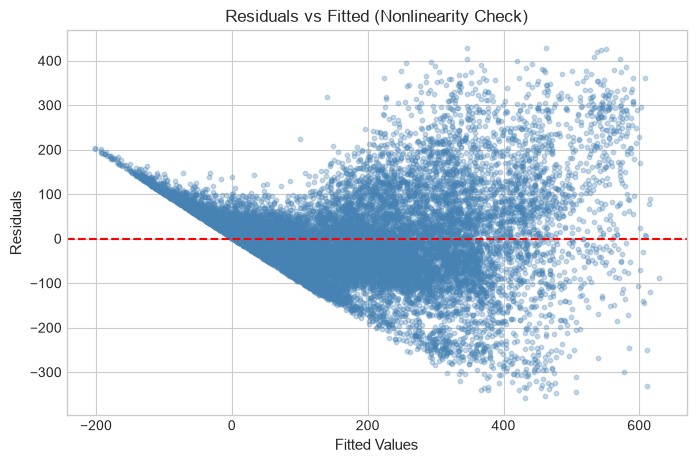

In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(m1_clean.fittedvalues, m1_clean.resid, alpha=0.3, s=10, color='steelblue')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Fitted (Nonlinearity Check)')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
A arc patten can be seen, this suggests the model is missing a non-linear term. On the right side of the plot, as the fitted value increase from 200 to 600, the vertical spread of the residual gets wider and wider looking like a funnel shape. The two shape proves both nonlinearity and heteroscedasticty (non constant variance)

## 7. Added Variable Plots (Continuous Predictor)
*Code: Generated by AI Assistant*

C:\Users\65831\AppData\Local\Temp\ipykernel_48864\748635037.py:9: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  plots.plot_partregress(
C:\Users\65831\AppData\Local\Temp\ipykernel_48864\748635037.py:21: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  plots.plot_partregress(


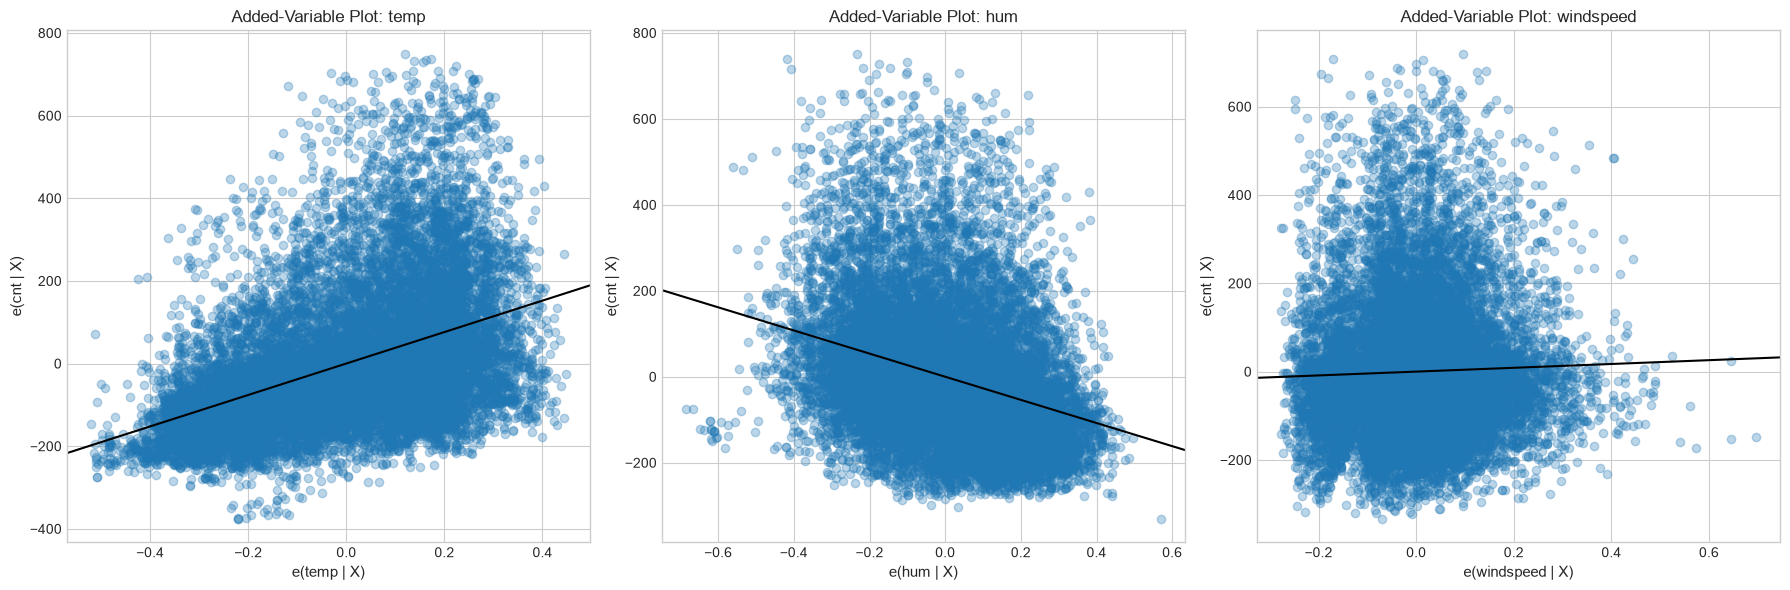

In [36]:
import statsmodels.graphics.regressionplots as plots
import matplotlib.pyplot as plt

# Set up a figure with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Added-Variable Plot for Temperature
# We pass the clean model (m1_clean), the variable of interest ('temp'), and the axes
plots.plot_partregress(
    endog='cnt', 
    exog_i='temp', 
    exog_others=['hum', 'windspeed'], 
    data=base_df, 
    ax=axes[0], 
    obs_labels=False, # Hides the row numbers so the plot isn't cluttered
    alpha=0.3
)
axes[0].set_title('Added-Variable Plot: temp')

# 2. Added-Variable Plot for Humidity
plots.plot_partregress(
    endog='cnt', 
    exog_i='hum', 
    exog_others=['temp', 'windspeed'], 
    data=base_df, 
    ax=axes[1], 
    obs_labels=False, 
    alpha=0.3
)
axes[1].set_title('Added-Variable Plot: hum')

# 3. Added-Variable Plot for Windspeed
plots.plot_partregress(
    endog='cnt', 
    exog_i='windspeed', 
    exog_others=['temp', 'hum'], 
    data=base_df, 
    ax=axes[2], 
    obs_labels=False, 
    alpha=0.3,
    result_object=False
)
axes[2].set_title('Added-Variable Plot: windspeed')

plt.tight_layout()
plt.show()

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
In general, as seen from the plot,  temp, hum and windspeed all has a highly non-linear relationship with cnt (bike demand). The straight regression line clearly miss the true curvature of all three variables.

